# Импорт данных IMNIST

In [1]:
from pathlib import Path

DATA_DIR = "./data"

pictureWidth = 28
pictureHeight = 28
imageHeaderSize = 16
labelHeaderSize = 8

def load_images(path):
    with open(path, "rb") as f:
        data = f.read()
    images = np.frombuffer(data, dtype=np.uint8, offset=imageHeaderSize)
    return images.reshape((len(data) - imageHeaderSize) // (pictureWidth * pictureHeight), pictureWidth, pictureHeight)

def load_labels(path):
    with open(path, "rb") as f:
        data = f.read()
    labels = np.frombuffer(data, dtype=np.uint8, offset=labelHeaderSize)
    return labels

In [4]:
import numpy as np

X_train = load_images(DATA_DIR + "/train-images.idx3-ubyte")
y_train = load_labels(DATA_DIR + "/train-labels.idx1-ubyte")

X_test = load_images(DATA_DIR + "/t10k-images.idx3-ubyte")
y_test = load_labels(DATA_DIR + "/t10k-labels.idx1-ubyte")

X_train.shape, y_train.shape, X_test.shape, y_test.shape

((60000, 28, 28), (60000,), (10000, 28, 28), (10000,))

# Вывод данных

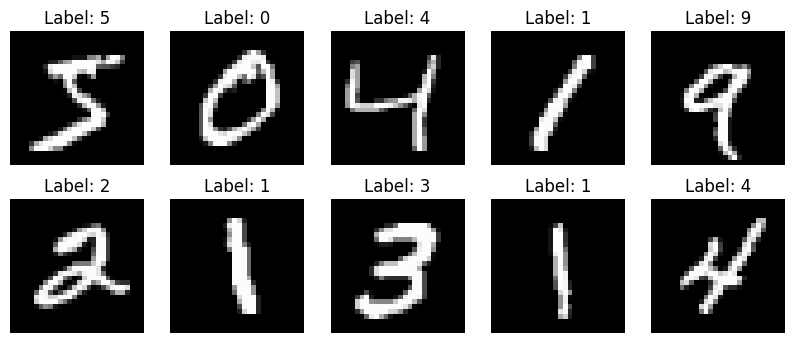

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i], cmap='gray')
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis('off')

# Предподготовка данных для обучения

In [129]:
X_train_norm = X_train.astype(np.float32) / 255
X_train_norm_reshaped = X_train_norm.reshape(X_train_norm.shape[0], -1)

Y_train_one_hot = np.zeros((y_train.size, y_train.max() + 1))
Y_train_one_hot[np.arange(y_train.size), y_train] = 1

X_test_norm = X_test.astype(np.float32) / 255
X_test_norm_reshaped = X_test_norm.reshape(X_test_norm.shape[0], -1)

Y_test_one_hot = np.zeros((y_test.size, y_test.max() + 1))
Y_test_one_hot[np.arange(y_test.size), y_test] = 1

# Класс модели

In [125]:
class NN:
    def __init__(self, input_size, hidden_size, output_size):
        self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2. / input_size)
        self.b1 = np.zeros(hidden_size)
        self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2. / hidden_size)
        self.b2 = np.zeros(output_size)
    
    def forward(self, X):
        self.X = X

        self.Z1 = X @ self.W1 + self.b1
        self.H = np.maximum(0, self.Z1)
        self.Z2 = self.H @ self.W2 + self.b2
        Z_shift = self.Z2 - self.Z2.max(axis=1, keepdims=True)
        exp_Z = np.exp(Z_shift)
        self.Y_hat = exp_Z / exp_Z.sum(axis=1, keepdims=True)

        return self.Y_hat

    def backward(self, Y):
        dZ2 = (self.Y_hat - Y) / Y.shape[0]

        self.derW2 = self.H.T @ dZ2
        self.derB2 = dZ2

        dZ1 = dZ2 @ self.W2.T
        dZ1[self.H <= 0] = 0

        self.derW1 = dZ1.T @ self.X
        self.derB1 = dZ1

    def update(self, learning_rate):
        self.W1 -= learning_rate * self.derW1.T
        self.b1 -= learning_rate * self.derB1.sum(axis=0)
        self.W2 -= learning_rate * self.derW2
        self.b2 -= learning_rate * self.derB2.sum(axis=0)

    def loss(self, Y):
        return -np.mean(np.sum(Y * np.log(self.Y_hat + 1e-9), axis=1))

    def predict(self, X):
        return np.argmax(self.forward(X), axis=1)


# Обучение модели

In [ ]:
import time

batch_size = 32
learning_rate = 0.1
epochs = 20

model = NN(784, 300, 10)
N = X_train_norm_reshaped.shape[0]

for epoch in range(epochs):
    start = time.time()

    perm = np.random.permutation(N)
    X_shuf = X_train_norm_reshaped[perm]
    Y_shuf = Y_train_one_hot[perm]

    for i in range(0, N, batch_size):
        Xb = X_shuf[i:i+batch_size]
        Yb = Y_shuf[i:i+batch_size]
        model.forward(Xb)
        model.backward(Yb)
        model.update(learning_rate)

    epoch_time = time.time() - start

    train_error = 1 - np.mean(model.predict(X_train_norm_reshaped) == y_train)
    print(f"Эпоха {epoch+1:2d}: ошибка на обучении = {train_error:.4f}, время = {epoch_time:.1f} с")

Эпоха  1: ошибка на обучении = 0.0432, время = 23.5 с
Эпоха  2: ошибка на обучении = 0.0292, время = 6.4 с
Эпоха  3: ошибка на обучении = 0.0205, время = 6.1 с
Эпоха  4: ошибка на обучении = 0.0152, время = 7.4 с
Эпоха  5: ошибка на обучении = 0.0123, время = 6.9 с
Эпоха  6: ошибка на обучении = 0.0087, время = 6.7 с
Эпоха  7: ошибка на обучении = 0.0079, время = 6.8 с
Эпоха  8: ошибка на обучении = 0.0062, время = 6.3 с
Эпоха  9: ошибка на обучении = 0.0040, время = 6.2 с
Эпоха 10: ошибка на обучении = 0.0052, время = 6.7 с
Эпоха 11: ошибка на обучении = 0.0024, время = 6.0 с
Эпоха 12: ошибка на обучении = 0.0015, время = 6.5 с
Эпоха 13: ошибка на обучении = 0.0014, время = 7.0 с
Эпоха 14: ошибка на обучении = 0.0011, время = 8.0 с
Эпоха 15: ошибка на обучении = 0.0007, время = 6.2 с
Эпоха 16: ошибка на обучении = 0.0007, время = 6.2 с
Эпоха 17: ошибка на обучении = 0.0004, время = 6.3 с
Эпоха 18: ошибка на обучении = 0.0003, время = 6.4 с
Эпоха 19: ошибка на обучении = 0.0002, время 

# Тестирование модели

In [130]:
test_error = 1 - np.mean(model.predict(X_test_norm_reshaped) == y_test)
print(f"Ошибка на тесте: {test_error:.4f}  (точность {1 - test_error:.2%})")

Ошибка на тесте: 0.0186  (точность 98.14%)
